# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [4]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [6]:
df = pd.read_csv('AviationData_cleaned.csv')

# People killed or seriously hurt, and as a fraction of everyone on board
df['Fatal.Serious.Count'] = df['Total.Fatal.Injuries'] + df['Total.Serious.Injuries']
df['Fatal.Serious.Rate'] = df['Fatal.Serious.Count'] / df['Total.Onboard']

print(df.shape)   


(53954, 31)


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [9]:
# Step 1: Calculate the 75th percentile of people onboard for each aircraft model
type_capacity = df.groupby("Make.Model")["Total.Onboard"].quantile(0.75)

# Step 2: Assign aircraft sizes based on the model's 75th percentile
df["Size"] = "Small"

large_models = type_capacity[type_capacity > 20].index

df.loc[df["Make.Model"].isin(large_models), "Size"] = "Large"

# Step 3: Separate small and large aircraft
small = df[df["Size"] == "Small"].copy()
large = df[df["Size"] == "Large"].copy()

# Step 4: Display the number of records in each group
print(df["Size"].value_counts())

# Step 5: Calculate mean fatal/serious injury rates
small_injury_rate = small["Fatal.Serious.Rate"].mean().round(3)
large_injury_rate = large["Fatal.Serious.Rate"].mean().round(3)

print("Mean fatal/serious injury rate:")
print("Small:", small_injury_rate)
print("Large:", large_injury_rate)

# Step 6: Calculate aircraft destruction rates
small_destroyed_rate = small["Destroyed"].mean().round(3)
large_destroyed_rate = large["Destroyed"].mean().round(3)

print("Destroyed rate:")
print("Small:", small_destroyed_rate)
print("Large:", large_destroyed_rate)

Size
Small    53339
Large      615
Name: count, dtype: int64
Mean fatal/serious injury rate:
Small: 0.276
Large: 0.182
Destroyed rate:
Small: 0.209
Large: 0.197


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

Small aircraft makes:
                                  n  mean_fs_rate  destroyed_rate
Make                                                             
BOMBARDIER                       14         0.093           0.071
GRUMMAN-SCHWEIZER               118         0.103           0.220
WACO                             97         0.132           0.103
GREAT LAKES                      54         0.139           0.111
MCDONNELL DOUGLAS                18         0.139           0.222
MAULE                           488         0.159           0.088
HELIO                            67         0.171           0.164
SCHWEIZER                       140         0.171           0.200
GRUMMAN                         924         0.178           0.228
BOEING                          328         0.189           0.131
WEATHERLY                        75         0.200           0.213
AVIAT                           221         0.201           0.063
WSK PZL MIELEC                   57         0.202     

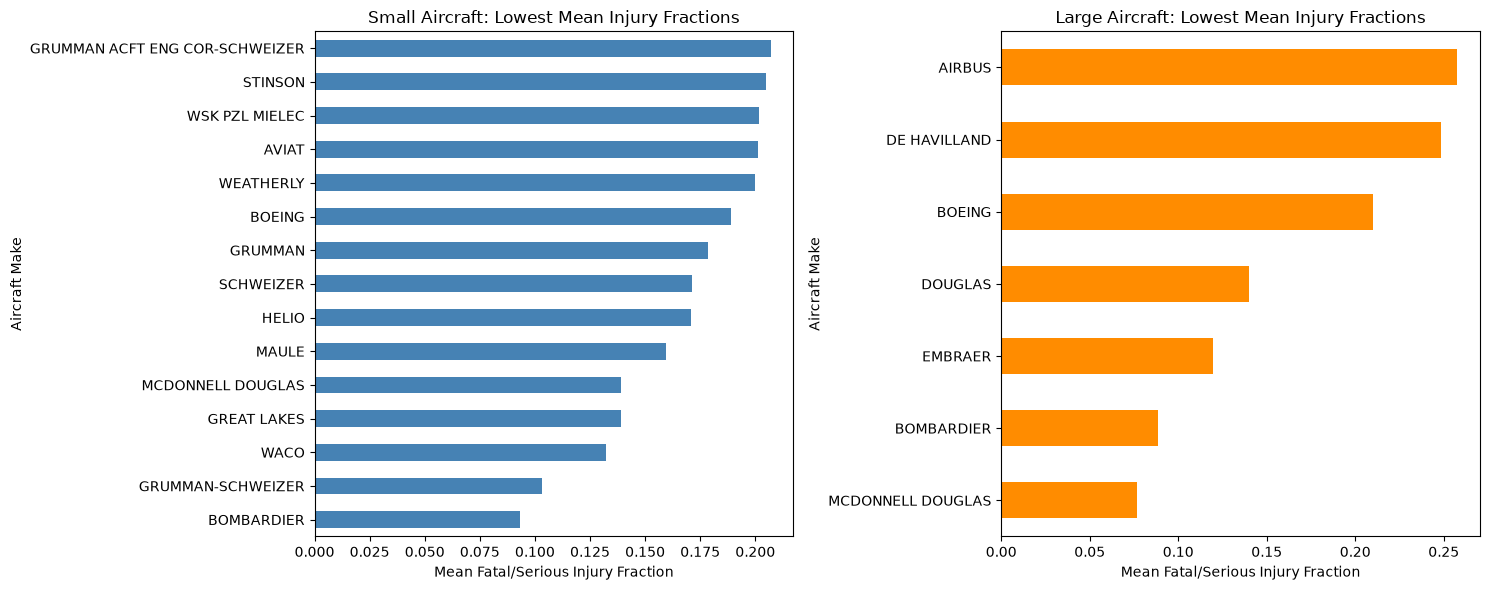

In [10]:
# Step 1: Create a function to summarize aircraft makes
def group_table(data, by, min_n=10):
    table = data.groupby(by).agg(
        n=("Destroyed", "count"),
        mean_fs_rate=("Fatal.Serious.Rate", "mean"),
        destroyed_rate=("Destroyed", "mean")
    )

    # Keep only makes with at least 10 records
    table = table[table["n"] >= min_n]

    return table


# Step 2: Summarize small and large aircraft by make
small_makes = group_table(small, "Make")
large_makes = group_table(large, "Make")


# Step 3: Select the 15 makes with the lowest mean injury rates
low_small = small_makes.sort_values(
    "mean_fs_rate", ascending=True
).head(15)

low_large = large_makes.sort_values(
    "mean_fs_rate", ascending=True
).head(15)


# Step 4: Display the results
print("Small aircraft makes:")
print(low_small.round(3))

print("\nLarge aircraft makes:")
print(low_large.round(3))


# Step 5: Create two bar charts
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Chart for small aircraft
small_chart = low_small.sort_values("mean_fs_rate", ascending=True)

small_chart["mean_fs_rate"].plot.barh(
    ax=axes[0], color="steelblue"
)

axes[0].set_title("Small Aircraft: Lowest Mean Injury Fractions")
axes[0].set_xlabel("Mean Fatal/Serious Injury Fraction")
axes[0].set_ylabel("Aircraft Make")


# Chart for large aircraft
large_chart = low_large.sort_values("mean_fs_rate", ascending=True)

large_chart["mean_fs_rate"].plot.barh(
    ax=axes[1], color="darkorange"
)

axes[1].set_title("Large Aircraft: Lowest Mean Injury Fractions")
axes[1].set_xlabel("Mean Fatal/Serious Injury Fraction")
axes[1].set_ylabel("Aircraft Make")


# Step 6: Display the charts
plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

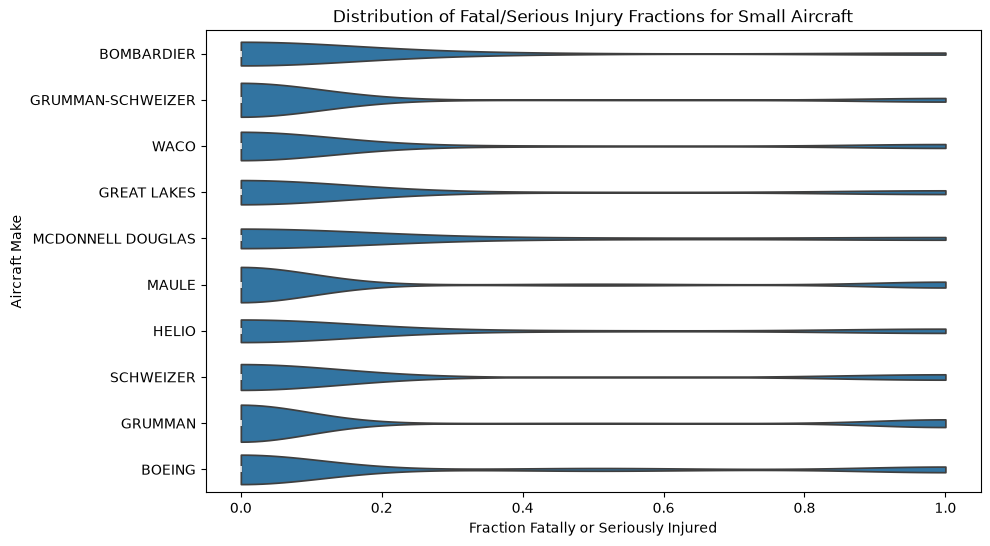

In [11]:
# Step 1: Select the 10 aircraft makes with the lowest mean injury rates
top10_small = (
    small_makes
    .nsmallest(10, "mean_fs_rate")
    .index
    .tolist()
)

# Step 2: Filter the data to include only those aircraft makes
selected_data = small[small["Make"].isin(top10_small)]

# Step 3: Create the violin plot
plt.figure(figsize=(10, 6))

sns.violinplot(
    x="Fatal.Serious.Rate",
    y="Make",
    data=selected_data,
    order=top10_small,
    cut=0
)

# Step 4: Add the chart title and axis label
plt.title("Distribution of Fatal/Serious Injury Fractions for Small Aircraft")
plt.xlabel("Fraction Fatally or Seriously Injured")
plt.ylabel("Aircraft Make")

# Step 5: Display the chart
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

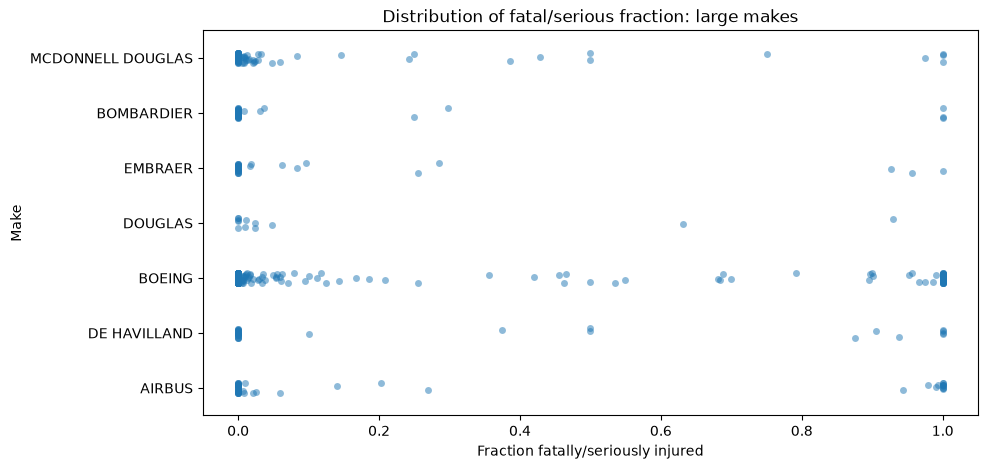

In [13]:
top10_large = large_makes.sort_values('mean_fs_rate').head(10).index   # only 7 qualify

plt.figure(figsize=(10, 5))
sns.stripplot(data=large[large['Make'].isin(top10_large)],
              x='Fatal.Serious.Rate', y='Make', order=top10_large, alpha=0.5)
plt.title('Distribution of fatal/serious fraction: large makes')
plt.xlabel('Fraction fatally/seriously injured')
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [15]:
# Step 1: Find the 15 aircraft makes with the lowest destruction rates
destroyed_small = small_makes.nsmallest(15, "destroyed_rate")
destroyed_large = large_makes.nsmallest(15, "destroyed_rate")

# Step 2: Round the results to 3 decimal places
small_results = destroyed_small.round(3)
large_results = destroyed_large.round(3)

# Step 3: Display the results
print("15 small aircraft makes with the lowest destruction rates:")
print(small_results)

print("\n15 large aircraft makes with the lowest destruction rates:")
print(large_results)

15 small aircraft makes with the lowest destruction rates:
                                  n  mean_fs_rate  destroyed_rate
Make                                                             
GRUMMAN ACFT ENG COR-SCHWEIZER   58         0.207           0.017
DIAMOND AIRCRAFT IND             72         0.229           0.056
AVIAT                           221         0.201           0.063
BOMBARDIER                       14         0.093           0.071
MAULE                           488         0.159           0.088
ERCOUPE                          72         0.350           0.097
LUSCOMBE                        362         0.230           0.099
AMERICAN CHAMPION                68         0.294           0.103
WACO                             97         0.132           0.103
GREAT LAKES                      54         0.139           0.111
TAYLORCRAFT                     318         0.300           0.113
GRUMMAN AMERICAN AVN             50         0.347           0.120
ROCKWELL INTERNAT

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

## Findings for Aircraft Makes

### Overview of the Results

The analysis indicates that most recorded aircraft accidents involved no serious injuries among the people on board. However, the outcomes varied across aircraft makes, particularly in terms of injury severity and whether the aircraft was destroyed. The violin and strip plots show that injury fractions are generally concentrated around zero, although some accidents resulted in much more severe outcomes.

### Small Aircraft

Maule, Aviat, and Stinson showed relatively favourable results among the small aircraft makes examined. They recorded low average fractions of fatal or serious injuries and comparatively low aircraft destruction rates. For Maule and Aviat, the destruction rate was approximately 10%, compared with about 20% for small aircraft overall.

These results are encouraging, particularly where there are enough accident records to support the comparison. Grumman also showed favourable injury outcomes, but its higher aircraft destruction rate makes its overall results less favourable.

### Large Aircraft

McDonnell Douglas, Bombardier, and Embraer performed relatively well in the comparison of large aircraft. They recorded some of the lowest average injury fractions and comparatively low destruction rates. Boeing had the largest number of observations and showed results closer to the overall average, while Airbus and De Havilland had less favourable outcomes relative to several other makes.

### Recommendations Based on the Analysis

- **Small aircraft:** Maule, Aviat, and Stinson showed favourable outcomes in the available accident data.
- **Large aircraft:** McDonnell Douglas, Bombardier, and Embraer showed relatively favourable results.

### Limitations

The findings should be interpreted cautiously. Only seven large aircraft makes met the minimum requirements for comparison, and most had fewer than 100 accident records. Therefore, small differences between makes may not represent meaningful differences in performance. Results for makes with limited observations, including Bombardier in the small-aircraft category, should also be treated cautiously.

These findings describe historical accident records and do not, on their own, establish which aircraft

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

                         n  mean_fs_rate  destroyed_rate
Make.Model                                              
MCDONNELL DOUGLAS MD88  17         0.003           0.000
MCDONNELL DOUGLAS MD80  10         0.011           0.000
BOMBARDIER CL6002C10    10         0.026           0.000
BOEING 727200           12         0.087           0.083
BOMBARDIER CL6002B19    21         0.098           0.095
BOEING 737300           15         0.109           0.200
BOEING 747              14         0.150           0.143
MCDONNELL DOUGLAS MD11  23         0.152           0.217
BOEING 767              13         0.176           0.231
BOEING 737              65         0.248           0.200
DE HAVILLAND DHC6300    21         0.293           0.333
BOEING 737400           10         0.384           0.500
BOEING 737200           21         0.517           0.571


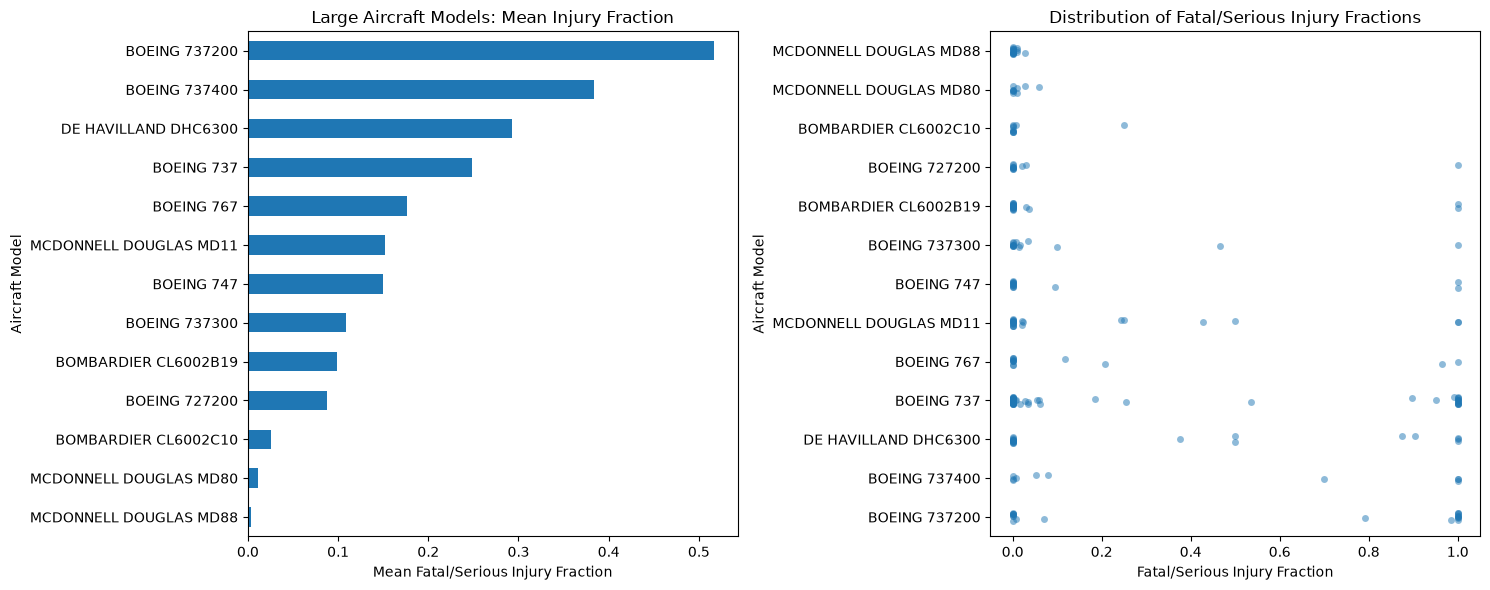

In [18]:
# Step 1: Summarize large aircraft models
large_types = group_table(large, "Make.Model")
large_types = large_types.sort_values(by="mean_fs_rate")

print(large_types.round(3))

# Step 2: Create two plots
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

# First plot: Mean injury fraction
large_types["mean_fs_rate"].plot(kind="barh", ax=ax[0])

ax[0].set_title("Large Aircraft Models: Mean Injury Fraction")
ax[0].set_xlabel("Mean Fatal/Serious Injury Fraction")
ax[0].set_ylabel("Aircraft Model")

# Second plot: Distribution of injury fractions
sns.stripplot(
    data=large[large["Make.Model"].isin(large_types.index)],
    x="Fatal.Serious.Rate",
    y="Make.Model",
    order=large_types.index.tolist(),
    alpha=0.5,
    ax=ax[1]
)

ax[1].set_title("Distribution of Fatal/Serious Injury Fractions")
ax[1].set_xlabel("Fatal/Serious Injury Fraction")
ax[1].set_ylabel("Aircraft Model")

# Step 3: Display both plots
plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

In [20]:
print("Rows in plot_data:", len(plot_data))
print(plot_data["Make.Model"].nunique())
print(plot_data["Fatal.Serious.Rate"].dtype)
print(plot_data["Fatal.Serious.Rate"].isna().sum())

Rows in plot_data: 890
15
float64
0


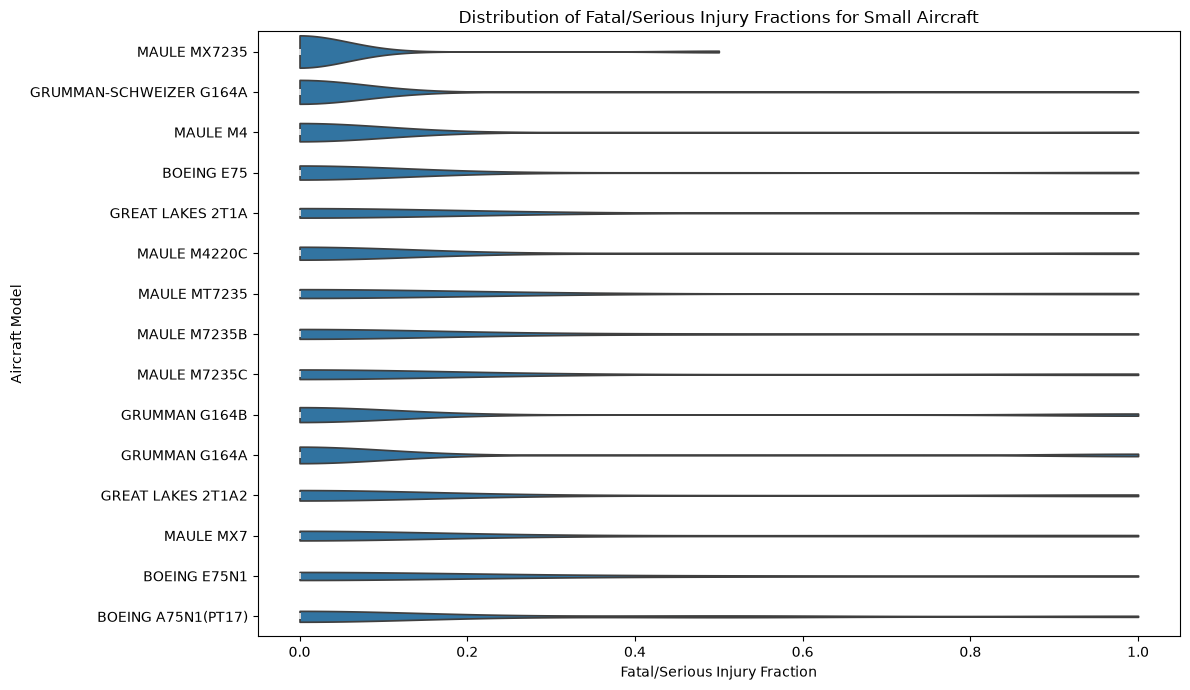

In [22]:
# Keep only rows with valid injury fractions and model names
violin_data = plot_data.dropna(
    subset=["Make.Model", "Fatal.Serious.Rate"]
).copy()

# Convert injury fractions to numeric values
violin_data["Fatal.Serious.Rate"] = pd.to_numeric(
    violin_data["Fatal.Serious.Rate"],
    errors="coerce"
)

violin_data = violin_data.dropna(
    subset=["Fatal.Serious.Rate"]
)

# Draw the violin plot
plt.figure(figsize=(12, 7))

sns.violinplot(
    data=violin_data,
    x="Fatal.Serious.Rate",
    y="Make.Model",
    order=[
        model for model in small_types.index
        if model in violin_data["Make.Model"].unique()
    ],
    cut=0
)

plt.title("Distribution of Fatal/Serious Injury Fractions for Small Aircraft")
plt.xlabel("Fatal/Serious Injury Fraction")
plt.ylabel("Aircraft Model")
plt.tight_layout()
plt.show()

                           n  mean_fs_rate  destroyed_rate
Make.Model                                                
MAULE MX7235              22         0.023           0.000
GRUMMAN-SCHWEIZER G164A   49         0.034           0.163
MAULE M4                  26         0.038           0.038
BOEING E75                33         0.076           0.121
GREAT LAKES 2T1A          11         0.091           0.091
MAULE M4220C              41         0.098           0.098
MAULE MT7235              10         0.100           0.000
MAULE M7235B              14         0.107           0.000
MAULE M7235C              18         0.111           0.056
GRUMMAN G164B            195         0.123           0.251
GRUMMAN G164A            355         0.127           0.225
GREAT LAKES 2T1A2         41         0.134           0.122
MAULE MX7                 24         0.135           0.000
BOEING E75N1              11         0.136           0.091
BOEING A75N1(PT17)        40         0.138           0.0

Text(0, 0.5, 'Aircraft Model')

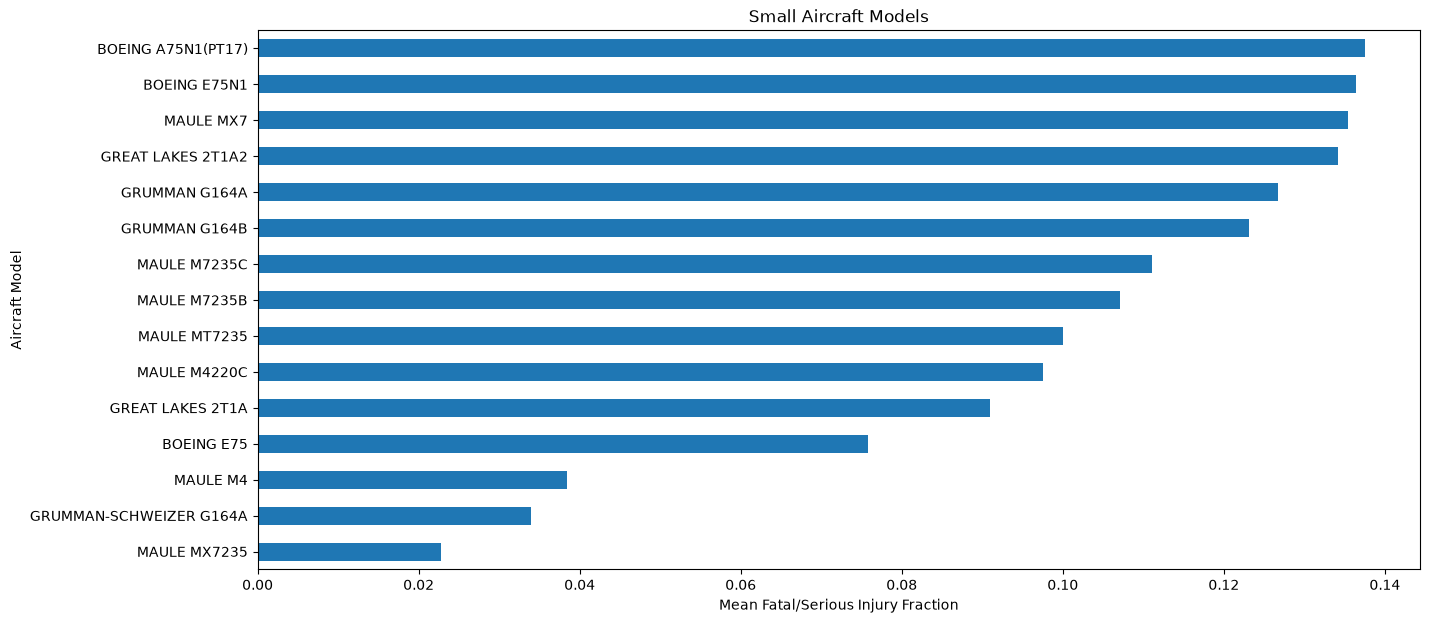

In [29]:
# Step 1: Filter small aircraft using the selected top 10 makes
small_top_makes = small[small["Make"].isin(top10_small)].copy()

# Step 2: Summarize accident outcomes for each aircraft model
small_types = group_table(small_top_makes, "Make.Model")

# Step 3: Sort models by mean injury fraction and select the first 15
small_types = small_types.sort_values(
    by="mean_fs_rate",
    ascending=True
).head(15)

# Display the summary table
print(small_types.round(3))

# Step 4: Keep accident records for the selected models
selected_models = small_types.index
plot_data = small_top_makes[
    small_top_makes["Make.Model"].isin(selected_models)
]

# Step 5: Create plot
fig, axes = plt.subplots(1, figsize=(15, 7))

# Bar chart of mean injury fractions
small_types["mean_fs_rate"].sort_values().plot(
    kind="barh",
    
)

plt.title("Small Aircraft Models")
plt.xlabel("Mean Fatal/Serious Injury Fraction")
plt.ylabel("Aircraft Model")

#

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

## Findings for Individual Aircraft Models

### Overview of the Results

The model-level analysis reveals differences that may not be visible when aircraft are compared by manufacturer alone. Aircraft belonging to the same make can have very different accident outcomes. Although most accidents involved no fatal or serious injuries, some models recorded more severe outcomes than others.

### Large Aircraft

The McDonnell Douglas MD-80 and MD-88, together with the Bombardier CL-600 variants, showed the most favourable results in the analysis. These models had very low proportions of fatal or serious injuries, and no aircraft destruction was recorded in the selected accident data. The Boeing 727-200 also demonstrated relatively favourable outcomes.

In contrast, the early Boeing 737-200 and 737-400 models had considerably poorer results, with approximately half of the people on board being fatally or seriously injured and around half of the aircraft being destroyed. Other Boeing 737 models fell between these extremes. This suggests that examining manufacturers alone may conceal important differences in accident outcomes between individual models.

### Small Aircraft

Among the selected small aircraft, Maule models recorded the lowest injury fractions, with most accidents involving no fatal or serious injuries. Grumman G164 models also showed favourable injury outcomes and had the largest number of observations, making their results comparatively more dependable.

However, Grumman models had higher aircraft destruction rates. Considering both injury outcomes and aircraft destruction, Maule models appeared to offer the more favourable results in this analysis.

### Recommendations

- **Large aircraft:** The McDonnell Douglas MD-80 and MD-88, along with Bombardier CL-600 variants, showed favourable outcomes in the available data. The early Boeing 737-200 and 737-400 models had less favourable results.
- **Small aircraft:** Maule models performed well when considering both injury fractions and aircraft destruction.

### Limitations of the Analysis

The results should be interpreted carefully because the large-aircraft models included approximately 10 to 65 accident records each. Models with smaller samples may have rankings that change substantially when only a few accident outcomes differ.

The analysis included only models with at least ten recorded accidents. In addition, the small-aircraft comparison was restricted to models from the ten selected makes. Therefore, the findings represent the available subset of accident records rather than all aircraft models.

Finally, these comparisons describe historical accident outcomes and should not be treated as definitive proof of aircraft safety. Factors such as operating conditions, maintenance, aircraft age, and the circumstances of each accident may also affect the results.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

                   n  destroyed_rate  mean_fs_rate
Engine.Type                                       
Turbo Fan        832           0.225         0.220
Reciprocating  50533           0.205         0.271
Turbo Jet        126           0.325         0.342
Turbo Prop      2316           0.288         0.365
p-value destroyed: 2.0475731852748765e-22 | p-value injury fraction: 2.641575636374141e-26


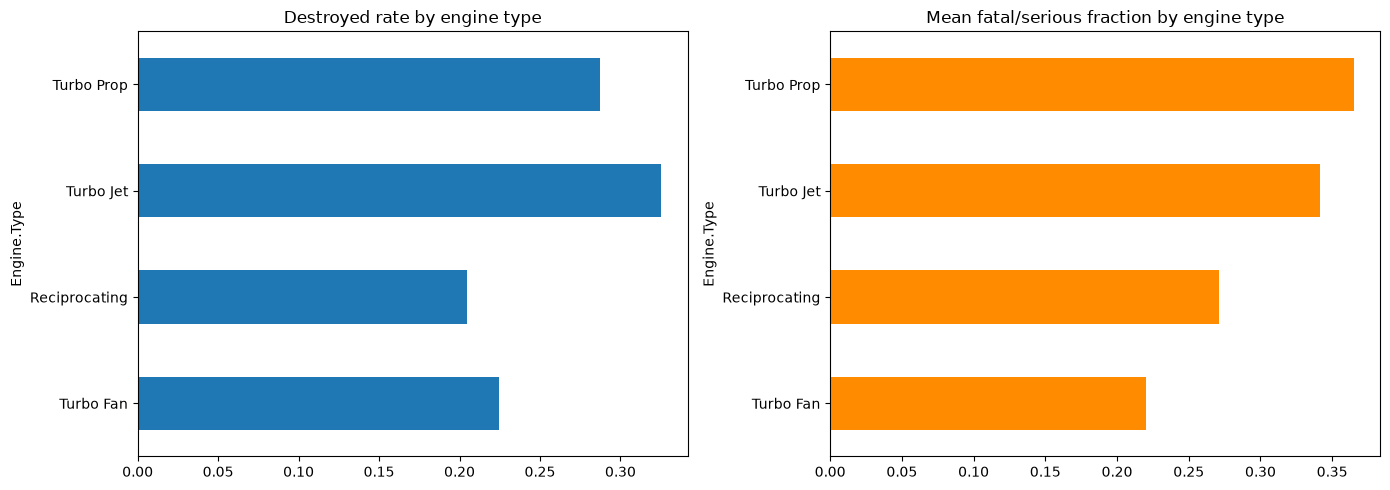

In [31]:
from scipy import stats

# Drop the few missing values, and engine types with fewer than 30 accidents
engine = df.dropna(subset=['Engine.Type'])
engine_counts = engine['Engine.Type'].value_counts()
engine = engine[engine['Engine.Type'].isin(engine_counts[engine_counts >= 30].index)]

engine_summary = engine.groupby('Engine.Type').agg(
    n=('Destroyed', 'size'),
    destroyed_rate=('Destroyed', 'mean'),
    mean_fs_rate=('Fatal.Serious.Rate', 'mean')
).sort_values('mean_fs_rate')
print(engine_summary.round(3))

# Are the differences real?
p_destroyed = stats.chi2_contingency(pd.crosstab(engine['Engine.Type'], engine['Destroyed']))[1]
p_rate = stats.kruskal(*[g['Fatal.Serious.Rate'].values for _, g in engine.groupby('Engine.Type')])[1]
print('p-value destroyed:', p_destroyed, '| p-value injury fraction:', p_rate)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
engine_summary['destroyed_rate'].plot.barh(ax=axes[0])
axes[0].set_title('Destroyed rate by engine type')
engine_summary['mean_fs_rate'].plot.barh(ax=axes[1], color='darkorange')
axes[1].set_title('Mean fatal/serious fraction by engine type')
plt.tight_layout()
plt.show()

## Interpretation of Results by Engine Type

The analysis shows that most recorded accidents involved piston (reciprocating) engines. Approximately 20% of these aircraft were destroyed. Turbo propeller and turbojet aircraft experienced more severe outcomes, with destruction rates of around 30% and a greater proportion of people on board suffering fatal or serious injuries. Turbofan aircraft recorded the lowest average injury fractions. The differences between engine types were statistically significant (\(p < 0.001\)). Turboshaft engines were excluded from the comparison because only 12 accident records were available.

### Limitations and Caution

Engine type is strongly associated with aircraft size and category, which may influence the results. Most turbofan engines are fitted to large aircraft carrying many passengers, meaning the injury fraction can be lower even when an accident is serious. In contrast, piston engines are predominantly used in smaller aircraft. When only small aircraft were considered, turbofan accidents showed higher injury severity than the average.

Therefore, the observed differences indicate an association between engine type and accident outcomes, but they do not establish that the engine type itself causes the differences. Other factors, including aircraft size, operating conditions, and accident circumstances, may also contribute to the observed patterns.

                           n  destroyed_rate  mean_fs_rate
Broad.phase.of.flight                                     
Taxi                    1228           0.020         0.017
Landing                10761           0.042         0.035
Standing                 409           0.127         0.093
Takeoff                 7932           0.216         0.227
Go-around               1084           0.286         0.299
Descent                 1121           0.336         0.352
Approach                4047           0.298         0.353
Cruise                  6420           0.345         0.356
Climb                   1209           0.444         0.444
Maneuvering             4181           0.464         0.525
p-value destroyed: 0.0 | p-value injury fraction: 0.0


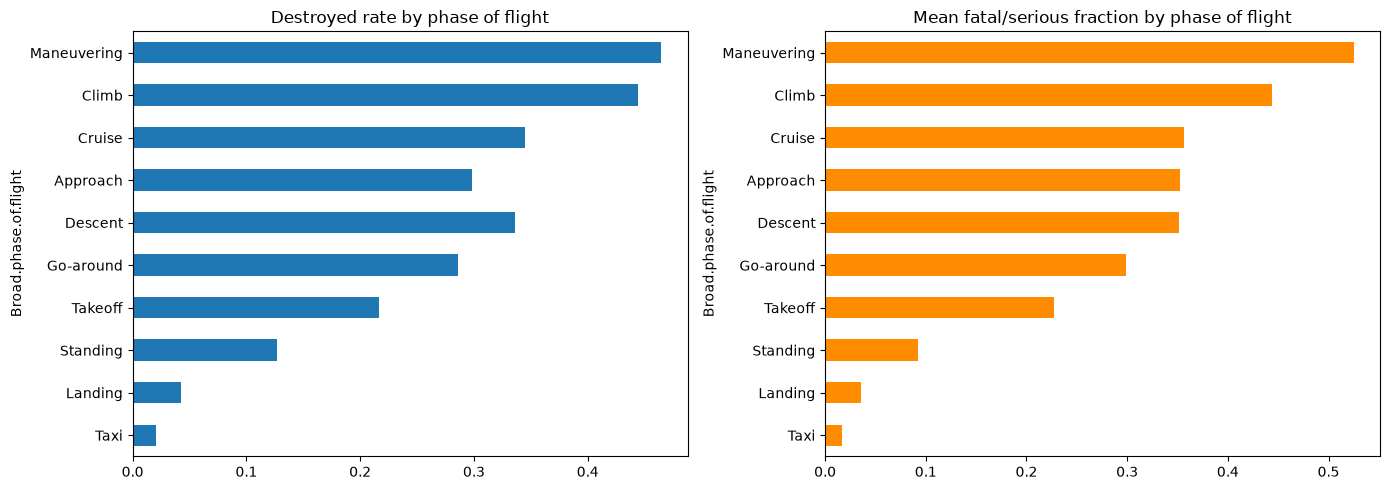

In [32]:
phase = df[~df['Broad.phase.of.flight'].isin(['Unknown', 'Other'])].dropna(subset=['Broad.phase.of.flight'])

phase_summary = phase.groupby('Broad.phase.of.flight').agg(
    n=('Destroyed', 'size'),
    destroyed_rate=('Destroyed', 'mean'),
    mean_fs_rate=('Fatal.Serious.Rate', 'mean')
).sort_values('mean_fs_rate')
print(phase_summary.round(3))

p_destroyed = stats.chi2_contingency(pd.crosstab(phase['Broad.phase.of.flight'], phase['Destroyed']))[1]
p_rate = stats.kruskal(*[g['Fatal.Serious.Rate'].values for _, g in phase.groupby('Broad.phase.of.flight')])[1]
print('p-value destroyed:', p_destroyed, '| p-value injury fraction:', p_rate)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
phase_summary['destroyed_rate'].plot.barh(ax=axes[0])
axes[0].set_title('Destroyed rate by phase of flight')
phase_summary['mean_fs_rate'].plot.barh(ax=axes[1], color='darkorange')
axes[1].set_title('Mean fatal/serious fraction by phase of flight')
plt.tight_layout()
plt.show()

## Interpretation of Results by Flight Phase

The findings indicate that accident severity varies considerably depending on the phase of flight. Taxiing and landing accidents generally had the least severe outcomes, with relatively few people experiencing fatal or serious injuries. Takeoff accidents showed moderate levels of severity, while cruise, climb, and maneuvering were associated with more serious outcomes. During maneuvering and climb, nearly half of the aircraft involved in accidents were destroyed.

Both charts show broadly similar rankings of accident severity across the different flight phases. The differences were statistically significant (\(p < 0.001\)), suggesting that accident outcomes vary meaningfully by flight phase.

Landing accounted for the largest number of recorded accidents, but these incidents were generally less severe than those occurring during other phases. Therefore, using accident frequency alone to assess risk could lead to misleading conclusions. For the client, it is important to consider both how often accidents occur and how severe their consequences are, with particular attention to injury rates and aircraft destruction.